<a href="https://colab.research.google.com/github/ocier7/latihan-knn-python/blob/main/M6_3KA26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [4]:
data = pd.read_csv('penjualan.csv')
display(data)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
395,46,41000,1
396,51,23000,1
397,50,20000,1
398,36,33000,0


In [5]:
#CEK MISSING VALUES
print(data.isnull().sum())

Age                0
EstimatedSalary    0
Purchased          0
dtype: int64


In [6]:
#PREPROCESSING VARIABEL X DAN Y
x = data[['Age','EstimatedSalary']]
y = data['Purchased']

display(x)
display(y)

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000
...,...,...
395,46,41000
396,51,23000
397,50,20000
398,36,33000


,Purchased
0,0
1,0
2,0
3,0
4,0
...,...
395,1
396,1
397,1
398,0


In [7]:
#NORMALISASI DENGAN SCALING
scaler = StandardScaler()
x = scaler.fit_transform(x)

#MENAMPILKAN VARIABEL X YANG SUDAH DI NORMALISASI
normalisasi = pd.DataFrame(x, columns=data[['Age','EstimatedSalary']].columns)
display(normalisasi)

,Age,EstimatedSalary
0,-1.781797,-1.490046
1,-0.253587,-1.460681
2,-1.113206,-0.785290
3,-1.017692,-0.374182
4,-1.781797,0.183751
...,...,...
395,0.797057,-0.844019
396,1.274623,-1.372587
397,1.179110,-1.460681
398,-0.158074,-1.078938


In [8]:
normalisasi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Age              400 non-null    float64
 1   EstimatedSalary  400 non-null    float64
dtypes: float64(2)
memory usage: 6.4 KB


In [9]:
#MEMISAHKAN DATA TRAINING DAN TESTING
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42)

In [10]:
#MEMBUAT MODEL
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [11]:
#EVALUASI MODEL
prediksi = knn.predict(X_test)

matriks = confusion_matrix(y_test, prediksi)
print("Confusion Matrix:\n", matriks)

skor_akurasi = accuracy_score(y_test, prediksi)
print("Accuracy Score:", skor_akurasi)

laporan = classification_report(y_test, prediksi)
print("Classification Report:\n", laporan)

Confusion Matrix:
 [[48  4]
 [ 2 26]]
Accuracy Score: 0.925
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.92      0.94        52
           1       0.87      0.93      0.90        28

    accuracy                           0.93        80
   macro avg       0.91      0.93      0.92        80
weighted avg       0.93      0.93      0.93        80



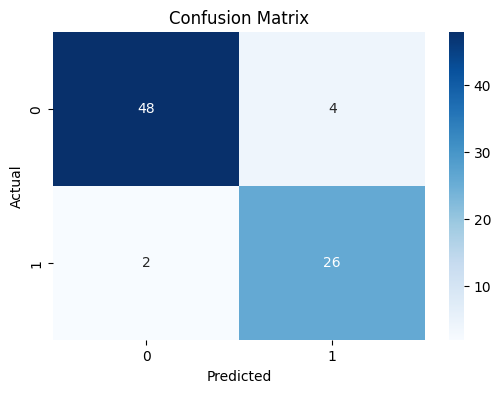

In [12]:
#VISUALISASI CONFUSSION MATRIKS
plt.figure(figsize=(6, 4))
sns.heatmap(matriks, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [13]:
#Perbandingan Data Asli dan Prediksi
hasil = pd.DataFrame({'Data Asli': y_test.values, 'Data Prediksi': prediksi})
hasil.head(20)

,Data Asli,Data Prediksi
0,0,1
1,1,1
2,0,0
3,1,1
4,0,0
5,0,0
6,1,1
7,0,0
8,0,0
9,0,0


In [14]:
#MENCARI NILAI K PALING BAIK
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 21, 25, 31, 35, 41, 45, 51]
accuracy_list = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred_k = knn.predict(X_test)
    acc_k = accuracy_score(y_test, y_pred_k)

    accuracy_list.append((k, acc_k))
    print(f"k = {k}, Accuracy = {acc_k:.4f}")

k = 3, Accuracy = 0.9250
k = 5, Accuracy = 0.9250
k = 7, Accuracy = 0.9375
k = 9, Accuracy = 0.9375
k = 11, Accuracy = 0.9250
k = 13, Accuracy = 0.9250
k = 15, Accuracy = 0.9250
k = 17, Accuracy = 0.9250
k = 21, Accuracy = 0.9250
k = 25, Accuracy = 0.9375
k = 31, Accuracy = 0.9375
k = 35, Accuracy = 0.9375
k = 41, Accuracy = 0.9375
k = 45, Accuracy = 0.9375
k = 51, Accuracy = 0.9250


=== EVALUASI MODEL K TERBAIK ===
Accuracy Score: 0.925

Confusion Matrix:
 [[48  4]
 [ 2 26]]

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.92      0.94        52
           1       0.87      0.93      0.90        28

    accuracy                           0.93        80
   macro avg       0.91      0.93      0.92        80
weighted avg       0.93      0.93      0.93        80



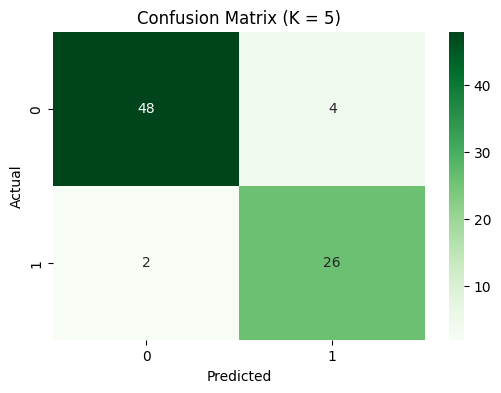


=== HASIL TESTING DATA BARU ===


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,Age,EstimatedSalary,Prediksi_Purchased
0,30,87000,0
1,48,35000,1


In [15]:
#TESTING DENGAN AKURASI TERBAIK
knn_best = KNeighborsClassifier(n_neighbors=5)
knn_best.fit(X_train, y_train)

prediksi_best = knn_best.predict(X_test)

print("=== EVALUASI MODEL K TERBAIK ===")
print("Accuracy Score:", accuracy_score(y_test, prediksi_best))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, prediksi_best))
print("\nClassification Report:\n", classification_report(y_test, prediksi_best))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, prediksi_best), annot=True, fmt='d', cmap='Greens')
plt.title(f'Confusion Matrix (K = {5})')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Misal ingin menguji pelanggan baru: Usia 30 tahun dengan Gaji 87000
data_baru = pd.DataFrame({'Age': [30, 48], 'EstimatedSalary': [87000, 35000]})

# Menggunakan .values untuk menghindari warning terkait feature names
data_baru_scaled = scaler.transform(data_baru.values)
prediksi_baru = knn_best.predict(data_baru_scaled)

data_baru['Prediksi_Purchased'] = prediksi_baru
print("\n=== HASIL TESTING DATA BARU ===")
display(data_baru)